**1: Ingestion & Baseline Feature Engineering**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns

plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)

# 1. Load the cleaned dataset from Notebook 01
df = pd.read_csv("kplc_clean_nse_data.csv")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

# 2. Compute essential liquidity & flow metrics
# Traded value in KES (Turnover)
df["Turnover_KES"] = df["Price"] * df["Volume"]

# Foreign Imbalance Ratio (bounded [-1, 1] approximation, zero when turnover is 0)
df["FIR"] = np.where(
    df["Turnover_KES"] > 0, df["Net_Foreign_Flow"] / df["Turnover_KES"], 0.0
)
# Clip extreme anomalies if auction prices caused turnover mismatch
df["FIR"] = df["FIR"].clip(-1.0, 1.0)

# Categorize trading regimes
conditions = [
    df["Net_Foreign_Flow"] > 0,
    df["Net_Foreign_Flow"] < 0,
    df["Net_Foreign_Flow"] == 0,
]
choices = ["Inflow", "Outflow", "Zero_Flow"]
df["Flow_Regime"] = np.select(conditions, choices, default="Zero_Flow")

print(f"Loaded {len(df)} cleaned trading days.")
print(df.head())

Loaded 2319 cleaned trading days.
        Date                                 Security  Price   Volume  \
0 2017-06-09  Kenya Power & Lighting  Co Ltd Ord 2.50   8.15        0   
1 2017-06-12  Kenya Power & Lighting  Co Ltd Ord 2.50   8.25  1640295   
2 2017-06-13  Kenya Power & Lighting  Co Ltd Ord 2.50   8.45        0   
3 2017-06-15  Kenya Power & Lighting  Co Ltd Ord 2.50   8.30        0   
4 2017-06-16  Kenya Power & Lighting  Co Ltd Ord 2.50   8.05        0   

   Net_Foreign_Flow  Daily_Return  Turnover_KES  FIR Flow_Regime  
0               0.0      0.000000          0.00  0.0   Zero_Flow  
1               0.0      0.012270   13532433.75  0.0   Zero_Flow  
2               0.0      0.024242          0.00  0.0   Zero_Flow  
3               0.0     -0.017751          0.00  0.0   Zero_Flow  
4               0.0     -0.030120          0.00  0.0   Zero_Flow  


**2: Liquidity & Foreign Participation Breakdown**

In [2]:
# Aggregate stats by regime
regime_stats = (
    df.groupby("Flow_Regime")
    .agg(
        Days=("Date", "count"),
        Avg_Price=("Price", "mean"),
        Avg_Volume=("Volume", "mean"),
        Avg_Turnover_KES=("Turnover_KES", "mean"),
        Mean_Daily_Return=("Daily_Return", "mean"),
        Std_Daily_Return=("Daily_Return", "std"),
        Median_Daily_Return=("Daily_Return", "median"),
    )
    .reset_index()
)

# Convert return values to clean percentage format
regime_stats["Mean_Daily_Return"] = (
    regime_stats["Mean_Daily_Return"] * 100
).round(3).astype(str) + "%"
regime_stats["Std_Daily_Return"] = (
    regime_stats["Std_Daily_Return"] * 100
).round(3).astype(str) + "%"
regime_stats["Median_Daily_Return"] = (
    regime_stats["Median_Daily_Return"] * 100
).round(3).astype(str) + "%"
regime_stats["Avg_Turnover_KES"] = (
    regime_stats["Avg_Turnover_KES"]
    .apply(lambda x: f"KES {x:,.0f}")
)

print("=== Market Characteristics by Foreign Flow Regime ===")
print(regime_stats.to_string(index=False))

=== Market Characteristics by Foreign Flow Regime ===
Flow_Regime  Days  Avg_Price   Avg_Volume Avg_Turnover_KES Mean_Daily_Return Std_Daily_Return Median_Daily_Return
     Inflow   493   6.611684 1.230277e+06    KES 8,364,164            0.277%           3.356%                0.0%
    Outflow   518   5.331873 1.149940e+06    KES 6,772,822            0.049%           2.543%                0.0%
  Zero_Flow  1308   3.606529 6.590072e+05    KES 2,386,694           -0.006%           2.417%                0.0%


**3: Rigorous Statistical Significance Testing (Hypothesis Validation)**

In [3]:
# Is the return difference between Inflows and Outflows statistically real?
inflow_rets = df[df["Flow_Regime"] == "Inflow"]["Daily_Return"]
outflow_rets = df[df["Flow_Regime"] == "Outflow"]["Daily_Return"]
zero_rets = df[df["Flow_Regime"] == "Zero_Flow"]["Daily_Return"]

# Welch's t-test (assumes unequal variances)
t_stat, p_val_t = stats.ttest_ind(inflow_rets, outflow_rets, equal_var=False)

# Mann-Whitney U test (non-parametric rank sum test, robust against heavy tails)
u_stat, p_val_u = stats.mannwhitneyu(
    inflow_rets, outflow_rets, alternative="two-sided"
)

print("=== Hypothesis Test: Do Foreign Inflow Days Outperform Outflow Days? ===")
print(
    f"Inflow Mean Return:  {inflow_rets.mean() * 100:+.4f}%  (Std: {inflow_rets.std() * 100:.3f}%)"
)
print(
    f"Outflow Mean Return: {outflow_rets.mean() * 100:+.4f}%  (Std: {outflow_rets.std() * 100:.3f}%)"
)
print(
    f"Zero Flow Return:    {zero_rets.mean() * 100:+.4f}%  (Std: {zero_rets.std() * 100:.3f}%)"
)
print("-" * 50)
print(f"Welch's t-test statistic: {t_stat:.4f}  |  p-value: {p_val_t:.4e}")
print(f"Mann-Whitney U statistic: {u_stat:.1f}  |  p-value: {p_val_u:.4e}")

if p_val_t < 0.05:
    print(
        "\nVerdict: Statistically SIGNIFICANT return divergence between inflow and outflow sessions (p < 0.05)."
    )
else:
    print(
        "\nVerdict: Statistically INSIGNIFICANT. Difference in same-day returns is within random market variance."
    )

=== Hypothesis Test: Do Foreign Inflow Days Outperform Outflow Days? ===
Inflow Mean Return:  +0.2771%  (Std: 3.356%)
Outflow Mean Return: +0.0486%  (Std: 2.543%)
Zero Flow Return:    -0.0057%  (Std: 2.417%)
--------------------------------------------------
Welch's t-test statistic: 1.2153  |  p-value: 2.2456e-01
Mann-Whitney U statistic: 129252.5  |  p-value: 7.3507e-01

Verdict: Statistically INSIGNIFICANT. Difference in same-day returns is within random market variance.


**Order Flow Autocorrelation (Testing Order Persistence)**

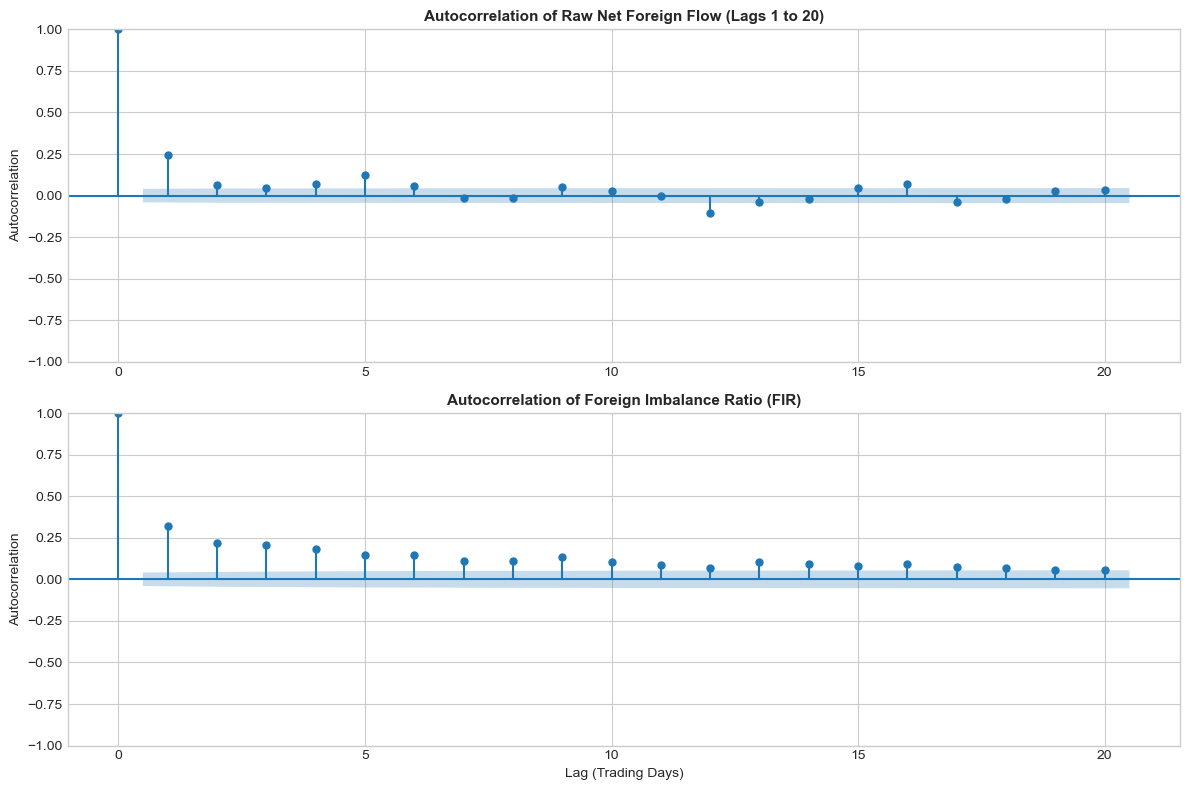

Autocorrelation values for Net Foreign Flow:
  Lag 1: +0.2438
  Lag 2: +0.0660
  Lag 3: +0.0486
  Lag 4: +0.0717
  Lag 5: +0.1242


In [4]:
# -------------------------------------------------------------------------
# Cell 4: Autocorrelation of Foreign Flows
# -------------------------------------------------------------------------
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# 1. Autocorrelation of raw daily net flow
plot_acf(df["Net_Foreign_Flow"], lags=20, ax=axes[0], alpha=0.05)
axes[0].set_title(
    "Autocorrelation of Raw Net Foreign Flow (Lags 1 to 20)",
    fontsize=11,
    fontweight="bold",
)
axes[0].set_ylabel("Autocorrelation")

# 2. Autocorrelation of Foreign Imbalance Ratio (FIR)
plot_acf(df["FIR"], lags=20, ax=axes[1], alpha=0.05)
axes[1].set_title(
    "Autocorrelation of Foreign Imbalance Ratio (FIR)",
    fontsize=11,
    fontweight="bold",
)
axes[1].set_ylabel("Autocorrelation")
axes[1].set_xlabel("Lag (Trading Days)")

plt.tight_layout()
plt.show()

# Print exact correlation numbers for first 5 lags
print("Autocorrelation values for Net Foreign Flow:")
for lag in range(1, 6):
    corr = df["Net_Foreign_Flow"].autocorr(lag=lag)
    print(f"  Lag {lag}: {corr:+.4f}")

**5: Predictive Lead-Lag Matrix (Information Decay)**

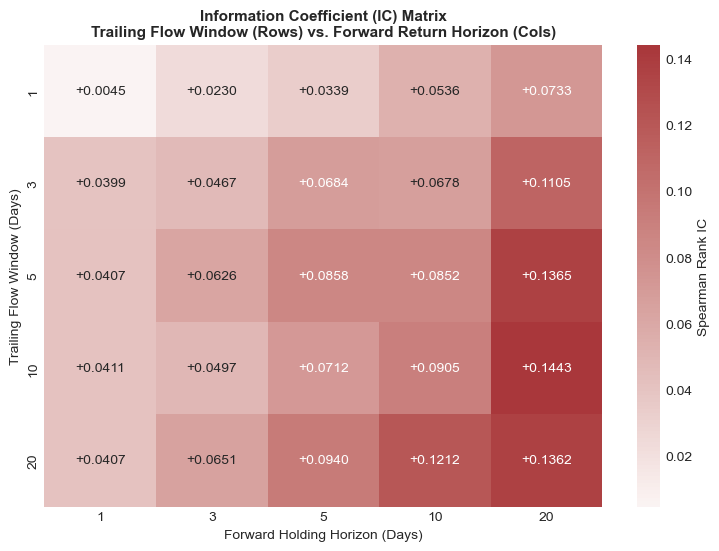

=== P-Values for IC Matrix (Green if p < 0.05) ===
         1        3        5        10       20
1    0.8305   0.2698   0.1032  0.0102*  0.0004*
3    0.0548  0.0247*  0.0010*  0.0011*  0.0000*
5    0.0501  0.0026*  0.0000*  0.0000*  0.0000*
10  0.0482*  0.0169*  0.0006*  0.0000*  0.0000*
20   0.0513  0.0018*  0.0000*  0.0000*  0.0000*


In [7]:
# -------------------------------------------------------------------------
# Cell 5: Lead-Lag Predictive Horizon Matrix
# -------------------------------------------------------------------------
# Feature: Cumulative rolling net flow (normalized by rolling turnover)
windows = [1, 3, 5, 10, 20]
forward_horizons = [1, 3, 5, 10, 20]

ic_matrix = pd.DataFrame(index=windows, columns=forward_horizons)
p_matrix = pd.DataFrame(index=windows, columns=forward_horizons)

for w in windows:
    # Trailing cumulative flow scaled by trailing turnover
    roll_flow = df["Net_Foreign_Flow"].rolling(w).sum()
    roll_turnover = df["Turnover_KES"].rolling(w).sum()
    signal = roll_flow / roll_turnover.replace(0, np.nan)

    for h in forward_horizons:
        # Forward return: Return from day t to day t+h
        fwd_return = df["Price"].shift(-h) / df["Price"] - 1.0

        # Valid pairs without lookahead
        valid = pd.DataFrame({"signal": signal, "target": fwd_return}).dropna()

        # Spearman Rank Correlation (Information Coefficient)
        spearman_corr, p_val = stats.spearmanr(valid["signal"], valid["target"])
        ic_matrix.loc[w, h] = spearman_corr
        p_matrix.loc[w, h] = p_val

ic_matrix = ic_matrix.astype(float)
p_matrix = p_matrix.astype(float)

plt.figure(figsize=(9, 6))
sns.heatmap(
    ic_matrix,
    annot=True,
    fmt="+.4f",
    cmap="vlag",
    center=0.0,
    cbar_kws={"label": "Spearman Rank IC"},
)
plt.title(
    "Information Coefficient (IC) Matrix\nTrailing Flow Window (Rows) vs. Forward Return Horizon (Cols)",
    fontsize=11,
    fontweight="bold",
)
plt.ylabel("Trailing Flow Window (Days)")
plt.xlabel("Forward Holding Horizon (Days)")
plt.show()

print("=== P-Values for IC Matrix (Green if p < 0.05) ===")
print(p_matrix.map(lambda x: f"{x:.4f}*" if x < 0.05 else f"{x:.4f}"))

**6: Structural Regime Breakdown (Pre-2024 vs Post-2024 Turnaround)**

In [8]:
# -------------------------------------------------------------------------
# Cell 6: Structural Regime Breakdown (Pre-2024 vs Post-2024 Turnaround)
# -------------------------------------------------------------------------
# Define the 10-day trailing flow signal and 20-day forward return target
roll_flow_10 = df["Net_Foreign_Flow"].rolling(10).sum()
roll_turnover_10 = df["Turnover_KES"].rolling(10).sum()
signal_10d = roll_flow_10 / roll_turnover_10.replace(0, np.nan)
fwd_return_20d = df["Price"].shift(-20) / df["Price"] - 1.0

eval_df = pd.DataFrame(
    {
        "Date": df["Date"],
        "Signal": signal_10d,
        "Target": fwd_return_20d,
        "Period": np.where(
            df["Date"] < "2024-01-01", "2017-2023 (Bear)", "2024-2026 (Bull)"
        ),
    }
).dropna()

for period, group in eval_df.groupby("Period"):
    ic, p = stats.spearmanr(group["Signal"], group["Target"])
    print(
        f"Regime: {period:<18} | Rank IC: {ic:+.4f} | p-value: {p:.4e} | Sessions: {len(group)}"
    )

Regime: 2017-2023 (Bear)   | Rank IC: +0.0700 | p-value: 4.0999e-03 | Sessions: 1678
Regime: 2024-2026 (Bull)   | Rank IC: +0.1167 | p-value: 3.8381e-03 | Sessions: 612


**Cell 7: Quantile Portfolio Monotonicity (Q1 to Q5 Forward Return Spread)**

=== 20-Day Forward Return Performance by Signal Quantile ===
       Quantile Mean_20D_Return Median_20D_Return Win_Rate  Sessions
Q1 (Heavy Sell)          -1.12%            -4.34%    34.3%       458
             Q2           0.49%            -1.85%    42.1%       458
             Q3           1.33%            -1.25%    44.8%       458
             Q4           2.27%            -0.67%    45.0%       458
 Q5 (Heavy Buy)           4.48%            -0.34%    47.4%       458


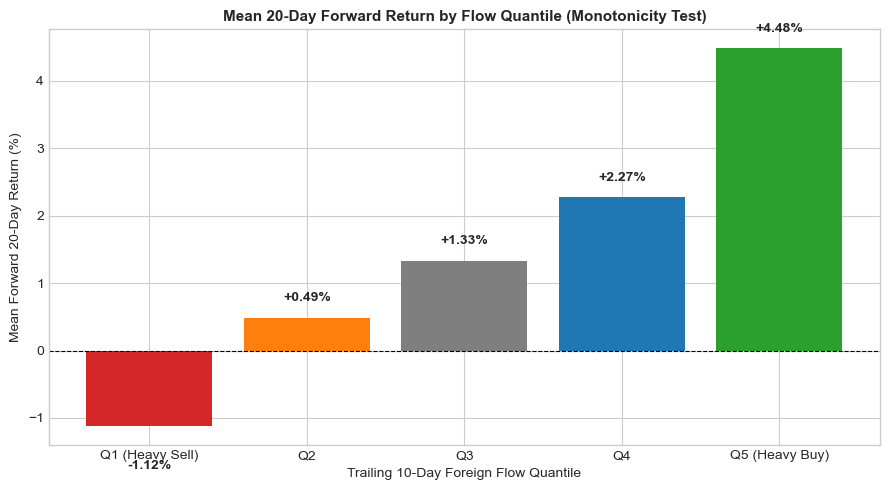

In [9]:
# -------------------------------------------------------------------------
# Cell 7: Quantile Portfolio Monotonicity (Q1 to Q5 Forward Return Spread)
# -------------------------------------------------------------------------
eval_df["Quantile"] = pd.qcut(
    eval_df["Signal"],
    q=5,
    labels=["Q1 (Heavy Sell)", "Q2", "Q3", "Q4", "Q5 (Heavy Buy)"],
)

quantile_perf = (
    eval_df.groupby("Quantile", observed=True)["Target"]
    .agg(
        Mean_20D_Return="mean",
        Median_20D_Return="median",
        Win_Rate=lambda x: (x > 0).mean(),
        Sessions="count",
    )
    .reset_index()
)

print("=== 20-Day Forward Return Performance by Signal Quantile ===")
quantile_perf["Mean_20D_Return"] = (
    (quantile_perf["Mean_20D_Return"] * 100).round(2).astype(str) + "%"
)
quantile_perf["Median_20D_Return"] = (
    (quantile_perf["Median_20D_Return"] * 100).round(2).astype(str) + "%"
)
quantile_perf["Win_Rate"] = (
    (quantile_perf["Win_Rate"] * 100).round(1).astype(str) + "%"
)
print(quantile_perf.to_string(index=False))

# Plot the monotonic return curve
plt.figure(figsize=(9, 5))
raw_means = (
    eval_df.groupby("Quantile", observed=True)["Target"].mean() * 100
)
bars = plt.bar(
    raw_means.index,
    raw_means.values,
    color=["#d62728", "#ff7f0e", "#7f7f7f", "#1f77b4", "#2ca02c"],
)
plt.axhline(0, color="black", linestyle="--", linewidth=0.8)
plt.title(
    "Mean 20-Day Forward Return by Flow Quantile (Monotonicity Test)",
    fontsize=11,
    fontweight="bold",
)
plt.ylabel("Mean Forward 20-Day Return (%)")
plt.xlabel("Trailing 10-Day Foreign Flow Quantile")
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + (0.2 if yval >= 0 else -0.5),
        f"{yval:+.2f}%",
        ha="center",
        va="bottom" if yval >= 0 else "top",
        fontweight="bold",
    )
plt.tight_layout()
plt.show()